<a href="https://colab.research.google.com/github/Cosmosmk2/FashionMNIST/blob/main/FashionMNIST_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import models, transforms
import torchvision.datasets as datasets
from torch.utils.data import Subset, random_split, DataLoader

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [3]:
training_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(0.3),
    transforms.RandomVerticalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5))
])
testing_evaluate_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5))
])

In [4]:
training = datasets.FashionMNIST(root = "data", train=True, download=True, transform=training_transform)
testing_set = datasets.FashionMNIST(root = "data", train = False, download = True, transform = testing_evaluate_transform)

training_split = int(len(training) * 0.8)
eval_split = len(training) - training_split

training_set, evalation_set = random_split(training, [training_split, eval_split])

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.7MB/s]


In [5]:
trainloader = DataLoader(training_set, batch_size=64, shuffle=True)
evalloader = DataLoader(evalation_set, batch_size=100, shuffle=False)
testloader = DataLoader(testing_set, batch_size=1000, shuffle=False)

In [6]:
i, m = next(iter(trainloader))

# i contains the batch of images, m contains the labels
# Let's inspect an image and a label from the batch, using a valid index (0 to 63):
print(m[0])

tensor(9)


In [7]:
classes = training.classes
classes

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [8]:
class FashionCNN(nn.Module):
    def __init__(self, loops, filters, stride, padding, k_size):
        super().__init__()
        # Use nn.ModuleList so PyTorch registers the layers correctly
        self.blocks = nn.ModuleList()

        in_channels = 1
        for i in range(loops):
            self.blocks.append(nn.Conv2d(in_channels = in_channels,
                                    out_channels = filters[i],
                                    kernel_size = k_size[i],
                                    stride = stride[i],
                                    padding = padding[i]))
            self.blocks.append(nn.ReLU())
            self.blocks.append(nn.BatchNorm2d(filters[i]))
            in_channels = filters[i]

        self.fc_layer = nn.Sequential(
            nn.AdaptiveAvgPool2d((2, 2)),
            nn.Flatten(),
            nn.Linear(filters[-1] * 2 * 2, 10)
        )

    def forward(self, x):
        for layer in self.blocks:
            x = layer(x)
        x = self.fc_layer(x)
        return x

In [9]:
model = FashionCNN(3, [3, 100, 300], [1,1,2], [1,1, 2],[3,3,3]).to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.0007)

In [12]:
def Training(loader, model, loss_function, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_index, (entry, label) in enumerate(loader):
        entry = entry.to(device)
        label = label.to(device)

        optimizer.zero_grad()
        output = model(entry)
        loss = loss_function(output, label)
        loss.backward()
        optimizer.step()

        _, predicted = output.max(1)
        total += label.size(0)
        correct += predicted.eq(label).sum().item()
        running_loss += loss.item()

        if batch_index % 100 == 0:
            loss = running_loss / (batch_index + 1)
            accuracy = 100 * correct / total
            print(f"Batch: {batch_index}| Loss: {loss:.4f}| Accuracy: {accuracy:.2f}%")


def Evaluation(loader, model, device):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for batch_index, (entry, label) in enumerate(loader):
            entry = entry.to(device)
            label = label.to(device)

            output = model(entry)
            _, predicted = output.max(1)

            total += label.size(0)
            correct += predicted.eq(label).sum().item()

            if batch_index % 500 == 0:
                accuracy = 100 * correct / total
                print(f"Evaluation: Accuracy: {accuracy:.2f}%")

In [13]:
epoch = 20

for epoch in range(epoch):
    print(f"Epoch: {epoch}")
    Training(trainloader, model, loss_function, optimizer, device)
    Evaluation(evalloader, model, device)

Epoch: 0
Batch: 0| Loss: 0.2280| Accuracy: 96.88%
Batch: 100| Loss: 0.2605| Accuracy: 90.75%
Batch: 200| Loss: 0.2597| Accuracy: 90.86%
Batch: 300| Loss: 0.2648| Accuracy: 90.61%
Batch: 400| Loss: 0.2651| Accuracy: 90.56%
Batch: 500| Loss: 0.2664| Accuracy: 90.52%
Batch: 600| Loss: 0.2651| Accuracy: 90.58%
Batch: 700| Loss: 0.2631| Accuracy: 90.64%
Evaluation: Accuracy: 89.00%
Epoch: 1
Batch: 0| Loss: 0.3808| Accuracy: 85.94%
Batch: 100| Loss: 0.2623| Accuracy: 90.76%
Batch: 200| Loss: 0.2523| Accuracy: 91.06%
Batch: 300| Loss: 0.2549| Accuracy: 90.91%
Batch: 400| Loss: 0.2529| Accuracy: 90.95%
Batch: 500| Loss: 0.2512| Accuracy: 91.03%
Batch: 600| Loss: 0.2533| Accuracy: 90.97%
Batch: 700| Loss: 0.2539| Accuracy: 90.97%
Evaluation: Accuracy: 89.00%
Epoch: 2
Batch: 0| Loss: 0.2447| Accuracy: 93.75%
Batch: 100| Loss: 0.2298| Accuracy: 91.97%
Batch: 200| Loss: 0.2322| Accuracy: 91.94%
Batch: 300| Loss: 0.2328| Accuracy: 91.90%
Batch: 400| Loss: 0.2317| Accuracy: 91.94%
Batch: 500| Loss: 

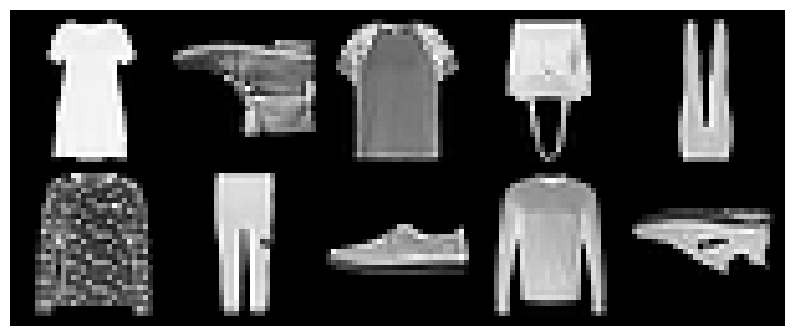

In [18]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils

# Get a batch of images
images, labels = next(iter(trainloader))

# Create a grid of 10 images (2 rows of 5)
grid = vutils.make_grid(images[:10], nrow=5, normalize=True)

# Convert grid from Torch tensor format (C, H, W) to Matplotlib format (H, W, C)
plt.figure(figsize=(10, 5))
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.show()

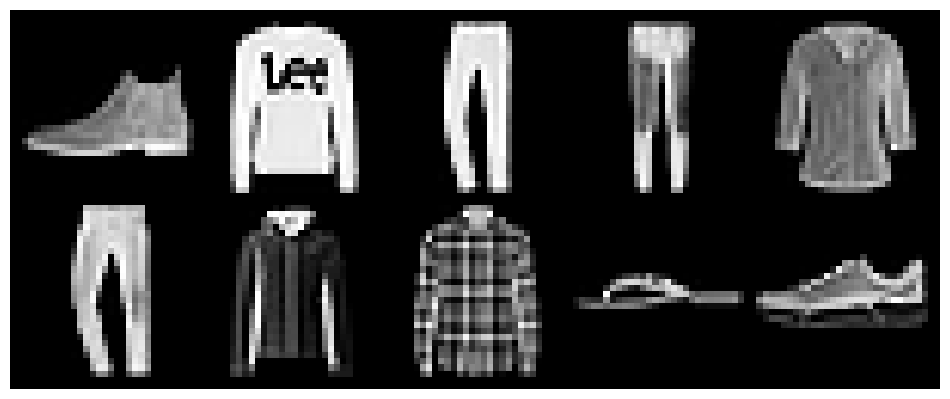

Grid layout (left to right, top to bottom):
Image  1: True: Ankle boot   | Pred: Ankle boot   ✓
Image  2: True: Pullover     | Pred: Pullover     ✓
Image  3: True: Trouser      | Pred: Trouser      ✓
Image  4: True: Trouser      | Pred: Trouser      ✓
Image  5: True: Shirt        | Pred: Shirt        ✓
Image  6: True: Trouser      | Pred: Trouser      ✓
Image  7: True: Coat         | Pred: Coat         ✓
Image  8: True: Shirt        | Pred: Shirt        ✓
Image  9: True: Sandal       | Pred: Sandal       ✓
Image 10: True: Sneaker      | Pred: Sneaker      ✓


In [16]:
import torch
import matplotlib.pyplot as plt
import torchvision.utils as vutils

# Set model to evaluation mode
model.eval()

# Get a batch of images and true labels
images, labels = next(iter(testloader))

# Take the first 10
inputs = images[:10].to(device)
true_labels = labels[:10]

# Get predictions from the model
with torch.no_grad():
    outputs = model(inputs)
    _, preds = torch.max(outputs, 1)

# Create the image grid
grid = vutils.make_grid(images[:10], nrow=5, normalize=True)

# Display the grid
plt.figure(figsize=(12, 6))
plt.imshow(grid.permute(1, 2, 0).cpu())
plt.axis('off')
plt.show()

# Print the Ground Truth vs Prediction for each image in the grid
print("Grid layout (left to right, top to bottom):")
for idx in range(10):
    true_name = classes[true_labels[idx]]
    pred_name = classes[preds[idx]]
    status = "✓" if true_name == pred_name else "✗"
    print(f"Image {idx+1:2d}: True: {true_name:<12} | Pred: {pred_name:<12} {status}")